# Exploratory Data Analysis (EDA)
# Load the data
I imported the tools I need and load the iris file into a table called df.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../datasets/1) iris.csv")
df.head()

To be sure that the dataset am working with is loaded i had to use the df.head() which is a function that reads the first 5 items in the dataset that am working on.

# display the loaded data
the data is read and loaded and displayed such that we can work on it.

In [5]:
print("Rows and columns:", df.shape)
df.info()

Rows and columns: (150, 5)
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


# get the number of rows and columns
the code above shows the rows and columns using the code df.shape()
The data has 150 rows and 5 columns. There are no missing values. A few rows are repeated.

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
Duplicate rows: 3


# outcome from above
the code above shows that the columns have no missing values using the .isnull() method and count them using the .sum() if at all there are any,but 3 duplicates are in the dataset


In [7]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

the .value_counts() counts the rows for each species such as setosa, versicolor and virginica. since each has 50, which means the data is balanced.

In [8]:
num_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

stats = df[num_cols].agg(["mean", "median", "std"])
stats.loc["mode"] = df[num_cols].mode().iloc[0]
stats.round(2)

,sepal_length,sepal_width,petal_length,petal_width
mean,5.84,3.05,3.76,1.20
median,5.80,3.00,4.35,1.30
std,0.83,0.43,1.76,0.76
mode,5.00,3.00,1.50,0.20



num_cols represents the list of the four measurement columns.
agg calculates the mean, median and std in one go/ at once 
The mode is added as an extra row. mode() can return several values, so .iloc[0] takes the first one.
# what the data means
- the mean shows the average between different columns and we see that the sepal length and petal lenght have different mean.
- the meadian shows the middle number when all the data has been sorted.
- the mode shows the number that has repeated the most times.
- the std shows how different columns vary / how values vary.
since sepal length has the wide spread of [1.76] than any other column.

In [9]:
df.groupby("species")[num_cols].mean().round(2)

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.42,1.46,0.24
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


# what the above code shows.
Petal length has the biggest spread compared to its average, so flowers differ a lot in petal size. For most columns the mean and median are close, so the data is fairly balanced. Virginica flowers have the largest measurements, and setosa the smallest petals.
so that is simply the small details about what the data above shows.

## Histograms
A histogram will show how the values of one column are spread out.

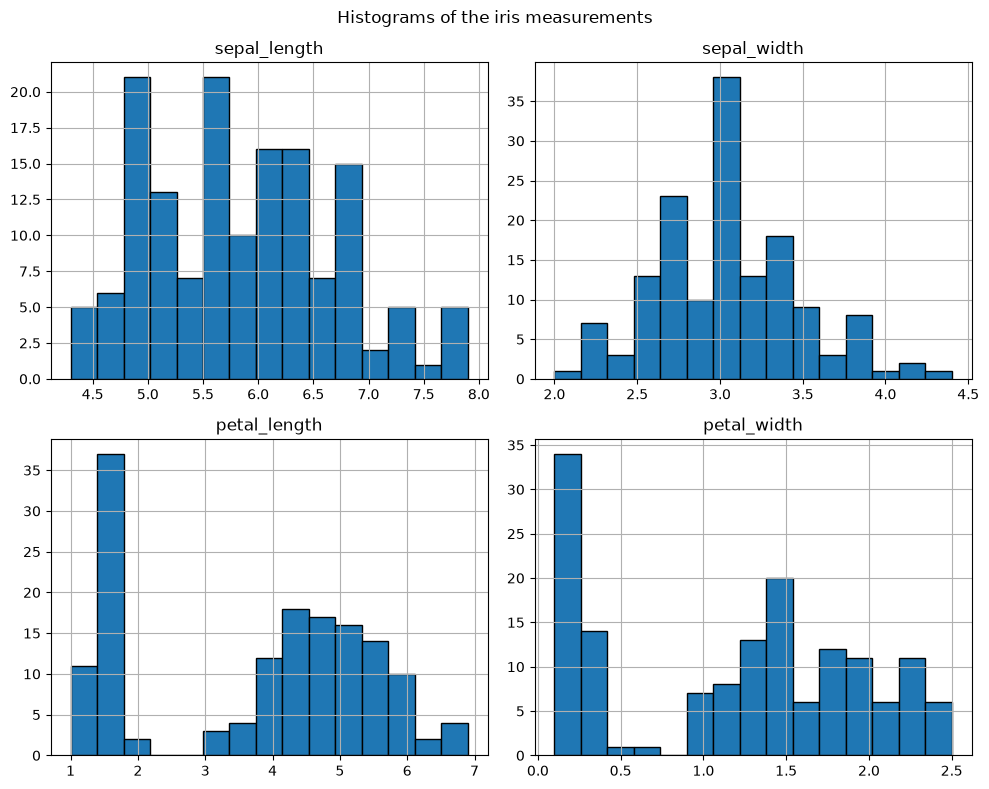

In [10]:
df[num_cols].hist(figsize=(10, 8), bins=15, edgecolor="black")
plt.suptitle("Histograms of the iris measurements")
plt.tight_layout()
plt.show()

- Sepal width is bell-shaped, with most flowers near the middle.
- Petal length and petal width show two separate clumps, with a gap between them. One clump is setosa’s tiny petals and the other is the larger petals of the other two species. That is why the mean and median of petal length differ.

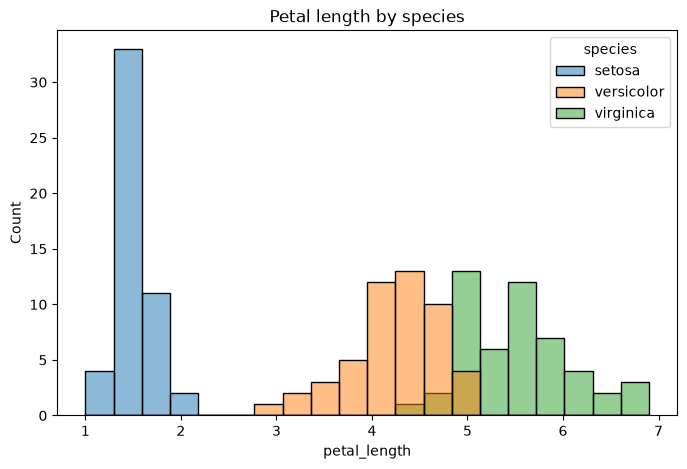

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="petal_length", hue="species", bins=20)
plt.title("Petal length by species")
plt.show()

Sepal width looks bell-shaped and balanced. Petal length and petal width have two clear groups, because setosa has much smaller petals than the other two species.

## Boxplots
A boxplot shows the middle of the data. The box holds the middle half of the values, the line inside is the median, and dots far away are outliers.

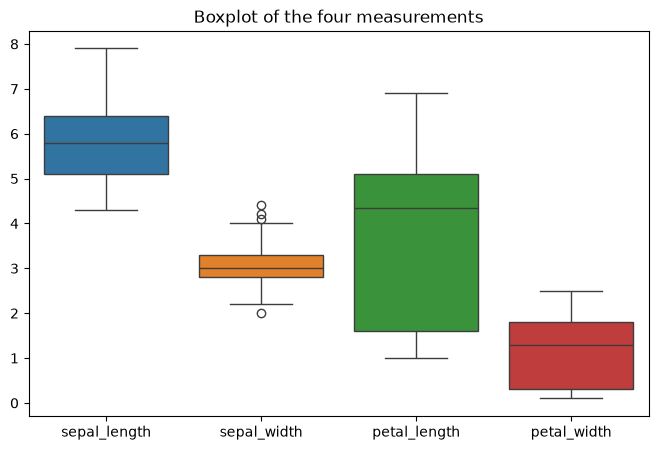

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[num_cols])
plt.title("Boxplot of the four measurements")
plt.show()

- The box holds the middle 50% of the values.
- The line inside is the median.
- The whiskers show the usual range.
- Dots outside the whiskers are outliers, unusually high or low values.

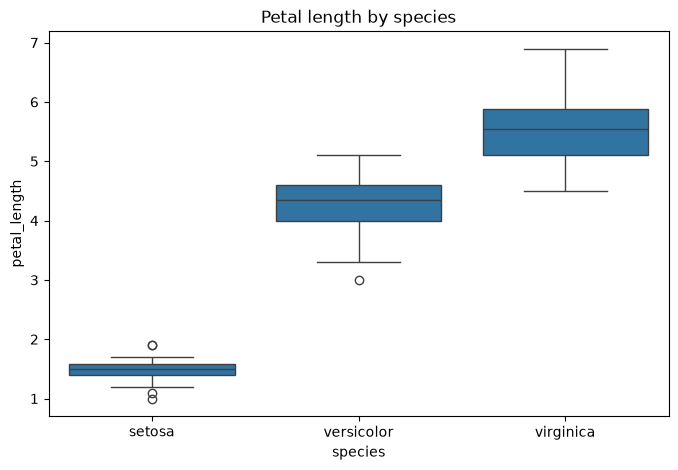

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="species", y="petal_length", data=df)
plt.title("Petal length by species")
plt.show()

Sepal width has a few outliers. Petal length is much smaller for setosa than for the other two species, and virginica has the largest petals.

## Scatter plots
A scatter plot shows how two columns relate. Each dot is one flower, and the colour shows its species.

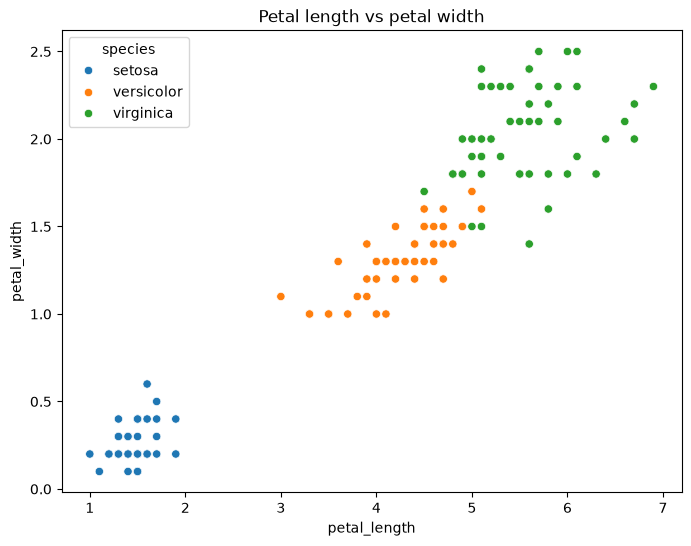

In [14]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x="petal_length", y="petal_width", hue="species", data=df)
plt.title("Petal length vs petal width")
plt.show()

# What we should note;

In petal length vs petal width, the dots rise together: longer petals are also wider.
Setosa forms its own island, far from the others.
Versicolor and virginica sit next to each other with a little overlap, which makes them the harder pair to separate.
In the sepal plot, the species are more mixed, so sepals are less useful for telling species apart than petals.

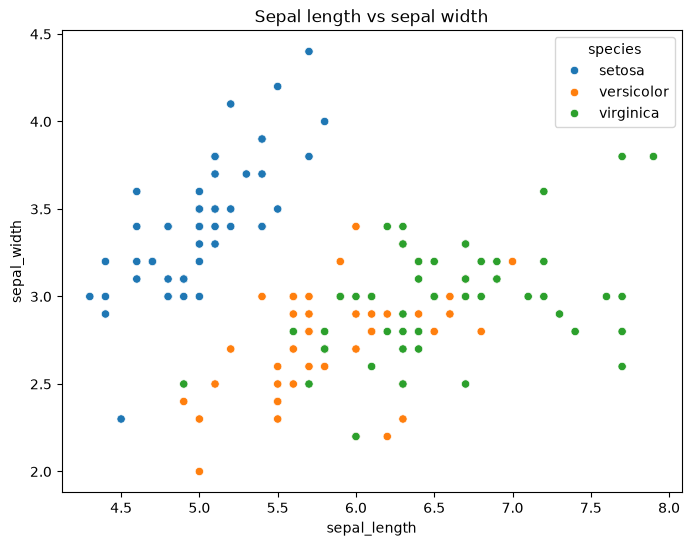

In [15]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x="sepal_length", y="sepal_width", hue="species", data=df)
plt.title("Sepal length vs sepal width")
plt.show()

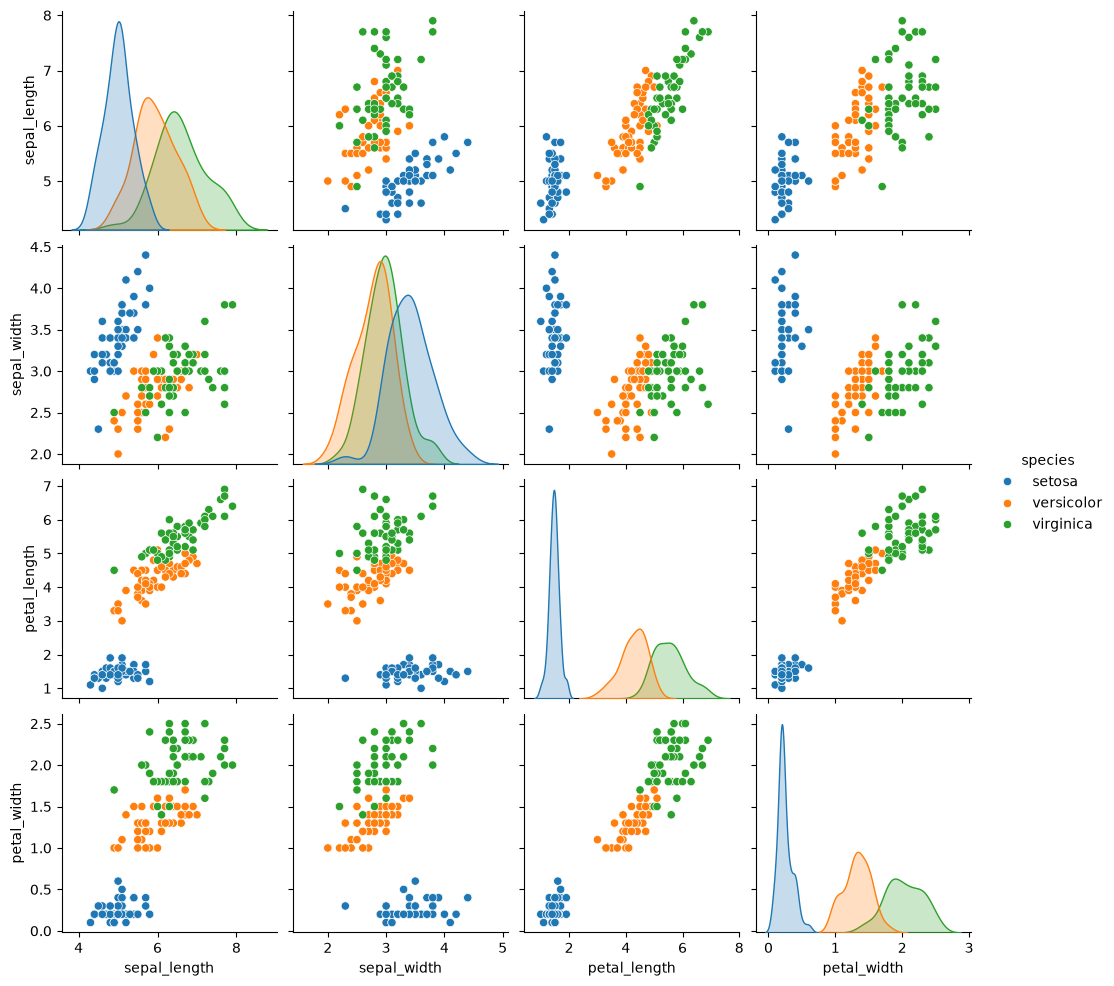

In [16]:
sns.pairplot(df, hue="species")
plt.show()

Petal length and petal width go up together. Setosa forms its own separate group, while versicolor and virginica overlap a little. The sepal plot shows more mixing between species.

## Correlation
Correlation shows how strongly two columns move together. It goes from -1 to 1.
- Close to 1: they rise together
- Close to -1: one rises as the other falls
- Close to 0: no clear link

In [17]:
corr = df[num_cols].corr()
corr.round(3)

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000,-0.109,0.872,0.818
sepal_width,-0.109,1.000,-0.421,-0.357
petal_length,0.872,-0.421,1.000,0.963
petal_width,0.818,-0.357,0.963,1.000


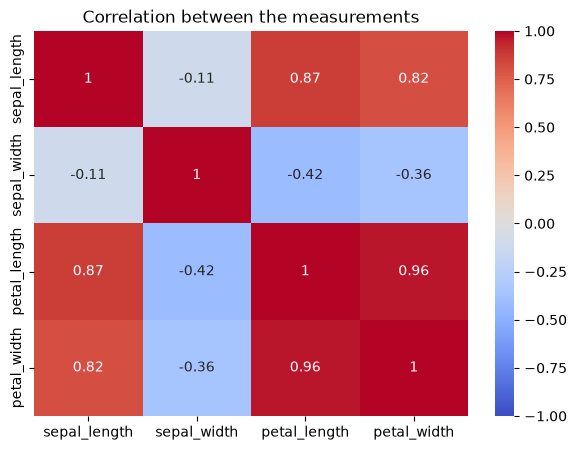

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between the measurements")
plt.show()

Petal length and petal width have a very strong positive correlation. Petal length is also strongly linked to sepal length. Sepal width has a weak or slightly negative link with the other columns.

## Summary
- The data has 150 rows and 5 columns, with no missing values.
- I calculated the mean, median, mode and standard deviation of each number column.
- Histograms showed that the petal columns have two groups.
- Boxplots showed that setosa has the smallest petals and virginica the largest.
- Scatter plots showed that setosa is clearly separate from the other two species.
- The strongest correlation was between petal length and petal width.